In [197]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [198]:
import pandas as pd

df = pd.read_csv("../Dataset/Grocery_Inventory_and_Sales_Dataset.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [199]:
# Check dataset dimensions
print("Rows and Columns:", df.shape)

# Display first 5 records
print("\nFirst 5 Records:")
display(df.head())

# Display all column names
print("\nColumn Names:")
print(df.columns.tolist())

Rows and Columns: (990, 16)

First 5 Records:


,Product_ID,Product_Name,Catagory,Supplier_ID,Supplier_Name,Stock_Quantity,Reorder_Level,Reorder_Quantity,Unit_Price,Date_Received,Last_Order_Date,Expiration_Date,Warehouse_Location,Sales_Volume,Inventory_Turnover_Rate,Status
0,29-205-1132,Sushi Rice,Grains & Pulses,38-037-1699,Jaxnation,22,72,70,$4.50,8/16/2024,6/29/2024,9/19/2024,48 Del Sol Trail,32,19,Discontinued
1,40-681-9981,Arabica Coffee,Beverages,54-470-2479,Feedmix,45,77,2,$20.00,11/1/2024,5/29/2024,5/8/2024,36 3rd Place,85,1,Discontinued
2,06-955-3428,Black Rice,Grains & Pulses,54-031-2945,Vinder,30,38,83,$6.00,8/3/2024,6/10/2024,9/22/2024,3296 Walton Court,31,34,Backordered
3,71-594-6552,Long Grain Rice,Grains & Pulses,63-492-7603,Brightbean,12,59,62,$1.50,12/8/2024,2/19/2025,4/17/2024,3 Westerfield Crossing,95,99,Active
4,57-437-1828,Plum,Fruits & Vegetables,54-226-4308,Topicstorm,37,30,74,$4.00,7/3/2024,10/11/2024,10/5/2024,15068 Scoville Court,62,25,Backordered



Column Names:
['Product_ID', 'Product_Name', 'Catagory', 'Supplier_ID', 'Supplier_Name', 'Stock_Quantity', 'Reorder_Level', 'Reorder_Quantity', 'Unit_Price', 'Date_Received', 'Last_Order_Date', 'Expiration_Date', 'Warehouse_Location', 'Sales_Volume', 'Inventory_Turnover_Rate', 'Status']


In [200]:
# Dataset information
print("DATASET INFORMATION")
df.info()

# Check missing values
print("\nMISSING VALUES")
print(df.isnull().sum())

# Check duplicate records
print("\nDUPLICATE ROWS")
print(df.duplicated().sum())

# Check data types
print("\nDATA TYPES")
print(df.dtypes)

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 990 entries, 0 to 989
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Product_ID               990 non-null    object
 1   Product_Name             990 non-null    object
 2   Catagory                 989 non-null    object
 3   Supplier_ID              990 non-null    object
 4   Supplier_Name            990 non-null    object
 5   Stock_Quantity           990 non-null    int64 
 6   Reorder_Level            990 non-null    int64 
 7   Reorder_Quantity         990 non-null    int64 
 8   Unit_Price               990 non-null    object
 9   Date_Received            990 non-null    object
 10  Last_Order_Date          990 non-null    object
 11  Expiration_Date          990 non-null    object
 12  Warehouse_Location       990 non-null    object
 13  Sales_Volume             990 non-null    int64 
 14  Inventory_Turnover_Rat

In [201]:
# Find the row with missing category

missing_category = df[df['Catagory'].isnull()]

display(missing_category)

,Product_ID,Product_Name,Catagory,Supplier_ID,Supplier_Name,Stock_Quantity,Reorder_Level,Reorder_Quantity,Unit_Price,Date_Received,Last_Order_Date,Expiration_Date,Warehouse_Location,Sales_Volume,Inventory_Turnover_Rate,Status
685,10-378-9729,Cabbage,NaN,83-941-9620,Rooxo,69,21,68,$66.55,12/23/2024,11/26/2024,9/21/2024,2 Butterfield Pass,36,35,Discontinued


In [202]:
# Check existing product categories

print("Existing Categories:")
print(df['Catagory'].value_counts(dropna=False))

Existing Categories:
Catagory
Fruits & Vegetables    331
Dairy                  180
Grains & Pulses        162
Seafood                 90
Oils & Fats             77
Beverages               75
Bakery                  74
NaN                      1
Name: count, dtype: int64


In [203]:
# Fill missing category based on product knowledge

df.loc[
    (df['Product_Name'] == 'Cabbage') & (df['Catagory'].isnull()),
    'Catagory'
] = 'Fruits & Vegetables'

# Verify missing values

print("Missing values after cleaning:")
print(df['Catagory'].isnull().sum())

Missing values after cleaning:
0


In [204]:
# Rename Catagory to Category

df.rename(columns={'Catagory': 'Category'}, inplace=True)

# Verify column name

print(df.columns.tolist())

['Product_ID', 'Product_Name', 'Category', 'Supplier_ID', 'Supplier_Name', 'Stock_Quantity', 'Reorder_Level', 'Reorder_Quantity', 'Unit_Price', 'Date_Received', 'Last_Order_Date', 'Expiration_Date', 'Warehouse_Location', 'Sales_Volume', 'Inventory_Turnover_Rate', 'Status']


In [205]:
# Remove dollar sign and convert Unit_Price to numeric

df['Unit_Price'] = (
    df['Unit_Price']
    .str.replace('$', '', regex=False)
    .astype(float)
)

# Check updated data type

print("Unit_Price Data Type:", df['Unit_Price'].dtype)

# Display first 5 prices

print(df['Unit_Price'].head())

Unit_Price Data Type: float64
0     4.5
1    20.0
2     6.0
3     1.5
4     4.0
Name: Unit_Price, dtype: float64


In [206]:
# STEP 15: Convert date columns into datetime

date_columns = [
    'Date_Received',
    'Last_Order_Date',
    'Expiration_Date'
]

for col in date_columns:
    df[col] = pd.to_datetime(df[col], errors='coerce')


# STEP 16: Check missing values

print("MISSING VALUES")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())


# STEP 17: Check updated data types

print("\nUPDATED DATA TYPES")
df.info()


# STEP 18: Statistical summary

print("\nSTATISTICAL SUMMARY")
display(df.describe())


# STEP 19: Final data quality report

print("\nFINAL DATA QUALITY REPORT")

print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])
print("Duplicate Rows:", df.duplicated().sum())
print("Total Missing Values:", df.isnull().sum().sum())

print("\nColumn Names:")
print(df.columns.tolist())

MISSING VALUES
Product_ID                 0
Product_Name               0
Category                   0
Supplier_ID                0
Supplier_Name              0
Stock_Quantity             0
Reorder_Level              0
Reorder_Quantity           0
Unit_Price                 0
Date_Received              0
Last_Order_Date            0
Expiration_Date            0
Warehouse_Location         0
Sales_Volume               0
Inventory_Turnover_Rate    0
Status                     0
dtype: int64

Total Missing Values: 0

UPDATED DATA TYPES
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 990 entries, 0 to 989
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   Product_ID               990 non-null    object        
 1   Product_Name             990 non-null    object        
 2   Category                 990 non-null    object        
 3   Supplier_ID              990 non-null    object 

,Stock_Quantity,Reorder_Level,Reorder_Quantity,Unit_Price,Date_Received,Last_Order_Date,Expiration_Date,Sales_Volume,Inventory_Turnover_Rate
count,990.000000,990.000000,990.000000,990.000000,990,990,990,990.000000,990.000000
mean,55.609091,51.215152,51.913131,5.924192,2024-08-23 02:18:10.909090816,2024-08-25 19:20:43.636363520,2024-08-23 06:45:49.090909184,58.925253,50.150505
min,10.000000,1.000000,1.000000,0.200000,2024-02-25 00:00:00,2024-02-25 00:00:00,2024-02-25 00:00:00,20.000000,1.000000
25%,33.000000,25.250000,25.000000,2.500000,2024-05-27 00:00:00,2024-05-29 00:00:00,2024-05-23 00:00:00,39.000000,25.000000
50%,56.000000,53.000000,54.000000,4.225000,2024-08-19 00:00:00,2024-08-20 12:00:00,2024-08-23 12:00:00,58.000000,50.000000
75%,79.000000,77.000000,77.000000,7.000000,2024-11-23 00:00:00,2024-11-29 00:00:00,2024-11-23 00:00:00,78.000000,74.750000
max,100.000000,100.000000,100.000000,98.430000,2025-02-24 00:00:00,2025-02-24 00:00:00,2025-02-24 00:00:00,100.000000,100.000000
std,26.300775,29.095241,29.521059,6.491280,NaN,NaN,NaN,23.002318,28.798954



FINAL DATA QUALITY REPORT
Total Rows: 990
Total Columns: 16
Duplicate Rows: 0
Total Missing Values: 0

Column Names:
['Product_ID', 'Product_Name', 'Category', 'Supplier_ID', 'Supplier_Name', 'Stock_Quantity', 'Reorder_Level', 'Reorder_Quantity', 'Unit_Price', 'Date_Received', 'Last_Order_Date', 'Expiration_Date', 'Warehouse_Location', 'Sales_Volume', 'Inventory_Turnover_Rate', 'Status']


In [207]:
# STEP 20: Overall Inventory Overview

print("INVENTORY OVERVIEW")

print("Total Products:", df['Product_ID'].nunique())
print("Total Stock Units:", df['Stock_Quantity'].sum())
print("Average Stock:", round(df['Stock_Quantity'].mean(), 2))
print("Total Sales Volume:", df['Sales_Volume'].sum())
print("Average Unit Price:", round(df['Unit_Price'].mean(), 2))


# STEP 21: Category-wise Inventory Analysis

category_analysis = df.groupby('Category').agg(
    Total_Products=('Product_ID', 'count'),
    Total_Stock=('Stock_Quantity', 'sum'),
    Total_Sales=('Sales_Volume', 'sum'),
    Average_Price=('Unit_Price', 'mean')
).reset_index()

display(category_analysis)


# STEP 22: Reorder Analysis

df['Stock_Status'] = np.where(
    df['Stock_Quantity'] <= df['Reorder_Level'],
    'Reorder Required',
    'Sufficient Stock'
)

print("\nREORDER STATUS")
print(df['Stock_Status'].value_counts())


# STEP 23: Preliminary Stockout Risk Screening

df['Stockout_Risk'] = np.where(
    df['Stock_Quantity'] < df['Sales_Volume'],
    'High Risk',
    'Low Risk'
)

print("\nSTOCKOUT RISK")
print(df['Stockout_Risk'].value_counts())


# STEP 24: Category-wise Risk Analysis

risk_analysis = df.groupby(
    ['Category', 'Stockout_Risk']
).size().unstack(fill_value=0)

print("\nCATEGORY-WISE RISK ANALYSIS")
display(risk_analysis)

INVENTORY OVERVIEW
Total Products: 990
Total Stock Units: 55053
Average Stock: 55.61
Total Sales Volume: 58336
Average Unit Price: 5.92


,Category,Total_Products,Total_Stock,Total_Sales,Average_Price
0,Bakery,74,4175,4564,4.063514
1,Beverages,75,3822,4533,15.998000
2,Dairy,180,10534,10772,4.508333
3,Fruits & Vegetables,332,18558,19397,4.795934
4,Grains & Pulses,162,8240,8886,3.848457
5,Oils & Fats,77,4123,4606,4.241558
6,Seafood,90,5601,5578,11.228889



REORDER STATUS
Stock_Status
Sufficient Stock    525
Reorder Required    465
Name: count, dtype: int64

STOCKOUT RISK
Stockout_Risk
High Risk    529
Low Risk     461
Name: count, dtype: int64

CATEGORY-WISE RISK ANALYSIS


Stockout_Risk,High Risk,Low Risk
Category,,
Bakery,39,35
Beverages,42,33
Dairy,88,92
Fruits & Vegetables,182,150
Grains & Pulses,89,73
Oils & Fats,46,31
Seafood,43,47


risk_percentage = (
    df['Stockout_Risk']
    .value_counts(normalize=True) * 100
)

print("STOCKOUT RISK PERCENTAGE")
print(risk_percentage.round(2))

In [208]:
risk_percentage = (
    df['Stockout_Risk']
    .value_counts(normalize=True) * 100
)

print("STOCKOUT RISK PERCENTAGE")
print(risk_percentage.round(2))

STOCKOUT RISK PERCENTAGE
Stockout_Risk
High Risk    53.43
Low Risk     46.57
Name: proportion, dtype: float64


In [209]:
category_risk_percentage = (
    pd.crosstab(
        df['Category'],
        df['Stockout_Risk'],
        normalize='index'
    ) * 100
)

print("CATEGORY-WISE STOCKOUT RISK PERCENTAGE")

display(category_risk_percentage.round(2))

CATEGORY-WISE STOCKOUT RISK PERCENTAGE


Stockout_Risk,High Risk,Low Risk
Category,,
Bakery,52.70,47.30
Beverages,56.00,44.00
Dairy,48.89,51.11
Fruits & Vegetables,54.82,45.18
Grains & Pulses,54.94,45.06
Oils & Fats,59.74,40.26
Seafood,47.78,52.22


In [210]:

print("INVENTORY STATUS ANALYSIS")

print("\nStatus Distribution:")
print(df['Status'].value_counts())

status_analysis = df.groupby('Status').agg(
    Total_Products=('Product_ID', 'count'),
    Total_Stock=('Stock_Quantity', 'sum'),
    Average_Stock=('Stock_Quantity', 'mean')
).reset_index()

print("\nStatus-wise Summary:")
display(status_analysis.round(2))

INVENTORY STATUS ANALYSIS

Status Distribution:
Status
Discontinued    333
Active          332
Backordered     325
Name: count, dtype: int64

Status-wise Summary:


,Status,Total_Products,Total_Stock,Average_Stock
0,Active,332,18689,56.29
1,Backordered,325,18135,55.80
2,Discontinued,333,18229,54.74


In [211]:
# STEP 28: Expiration Date Analysis

df['Days_To_Expiry'] = (
    df['Expiration_Date'] -
    pd.Timestamp.today().normalize()
).dt.days

print("EXPIRATION DATE ANALYSIS")

print(
    "Already Expired:",
    (df['Days_To_Expiry'] < 0).sum()
)

print(
    "Expiring Within 30 Days:",
    (
        (df['Days_To_Expiry'] >= 0) &
        (df['Days_To_Expiry'] <= 30)
    ).sum()
)

print(
    "Expiring Within 90 Days:",
    (
        (df['Days_To_Expiry'] >= 0) &
        (df['Days_To_Expiry'] <= 90)
    ).sum()
)

EXPIRATION DATE ANALYSIS
Already Expired: 990
Expiring Within 30 Days: 0
Expiring Within 90 Days: 0


In [212]:
df['Expiry_Status'] = np.select(
    [
        df['Days_To_Expiry'] < 0,
        df['Days_To_Expiry'].between(0, 30),
        df['Days_To_Expiry'].between(31, 90)
    ],
    [
        'Expired',
        'Expiring Soon',
        'Expiring Within 90 Days'
    ],
    default='Safe'
)

print(df['Expiry_Status'].value_counts())

Expiry_Status
Expired    990
Name: count, dtype: int64


In [213]:
supplier_analysis = df.groupby('Supplier_Name').agg(
    Total_Products=('Product_ID', 'count'),
    Total_Stock=('Stock_Quantity', 'sum'),
    Average_Stock=('Stock_Quantity', 'mean'),
    Total_Sales=('Sales_Volume', 'sum')
).reset_index()

supplier_analysis = supplier_analysis.sort_values(
    by='Total_Stock',
    ascending=False
)

display(supplier_analysis.head(10).round(2))

,Supplier_Name,Total_Products,Total_Stock,Average_Stock,Total_Sales
138,Katz,12,701,58.42,800
293,Twitterwire,7,538,76.86,393
165,Meevee,10,513,51.30,534
205,Quatz,9,460,51.11,558
91,Feedfire,5,439,87.80,252
208,Quinu,7,398,56.86,300
172,Mybuzz,6,397,66.17,300
65,Devshare,6,374,62.33,366
36,Bubblemix,5,363,72.60,358
194,Photobug,7,357,51.00,468


In [214]:
expiry_analysis = df.groupby('Expiry_Status').agg(
    Total_Products=('Product_ID', 'count'),
    Total_Stock=('Stock_Quantity', 'sum'),
    Average_Stock=('Stock_Quantity', 'mean')
).reset_index()

display(expiry_analysis.round(2))

,Expiry_Status,Total_Products,Total_Stock,Average_Stock
0,Expired,990,55053,55.61


In [215]:
# STEP 32: Warehouse Analysis

warehouse_analysis = df.groupby('Warehouse_Location').agg(
    Total_Products=('Product_ID', 'count'),
    Total_Stock=('Stock_Quantity', 'sum'),
    Average_Stock=('Stock_Quantity', 'mean'),
    Total_Sales=('Sales_Volume', 'sum')
).reset_index()

warehouse_analysis = warehouse_analysis.sort_values(
    by='Total_Stock',
    ascending=False
)

display(warehouse_analysis.round(2))

,Warehouse_Location,Total_Products,Total_Stock,Average_Stock,Total_Sales
426,4029 Lotheville Pass,1,100,100.0,76
576,56 Esker Park,1,100,100.0,86
873,8626 Chinook Parkway,1,100,100.0,84
404,4 Browning Terrace,1,100,100.0,77
432,41 Nelson Center,1,100,100.0,98
...,...,...,...,...,...
273,27 New Castle Avenue,1,11,11.0,40
397,39 Lakewood Gardens Center,1,11,11.0,88
919,91 Gateway Pass,1,10,10.0,29
100,1 Jackson Pass,1,10,10.0,100


In [216]:
print("Total Warehouse Locations:",
      df['Warehouse_Location'].nunique())

print("Products per Warehouse:")
print(
    df.groupby('Warehouse_Location')['Product_ID']
    .count()
    .value_counts()
)

Total Warehouse Locations: 990
Products per Warehouse:
Product_ID
1    990
Name: count, dtype: int64


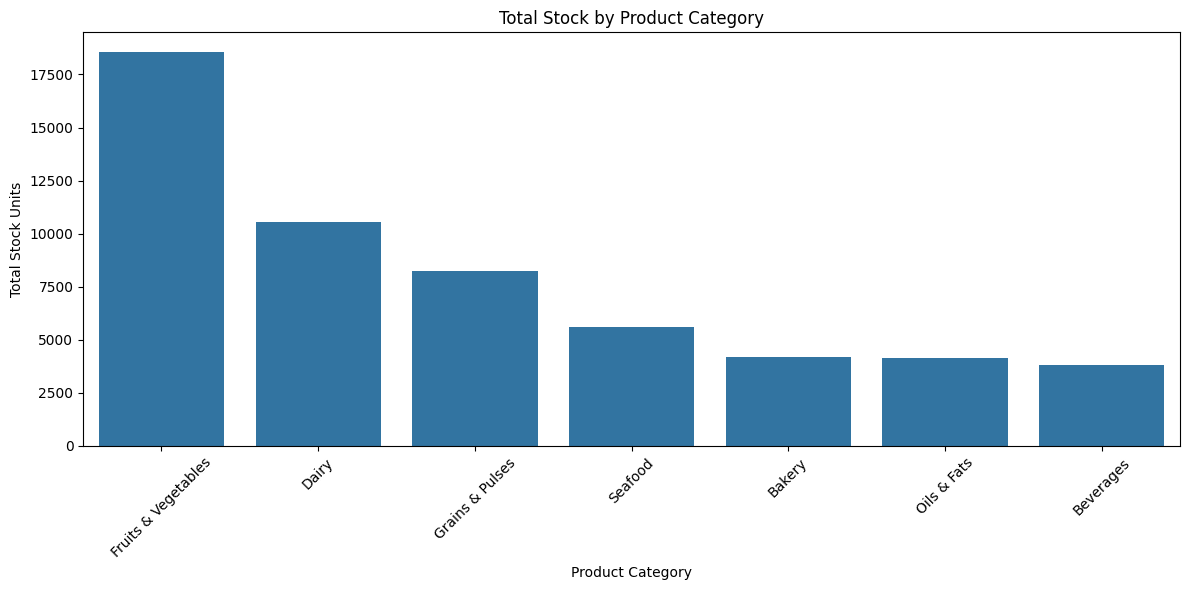

In [217]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=category_analysis.sort_values(
        by='Total_Stock',
        ascending=False
    ),
    x='Category',
    y='Total_Stock'
)

plt.title('Total Stock by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Stock Units')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

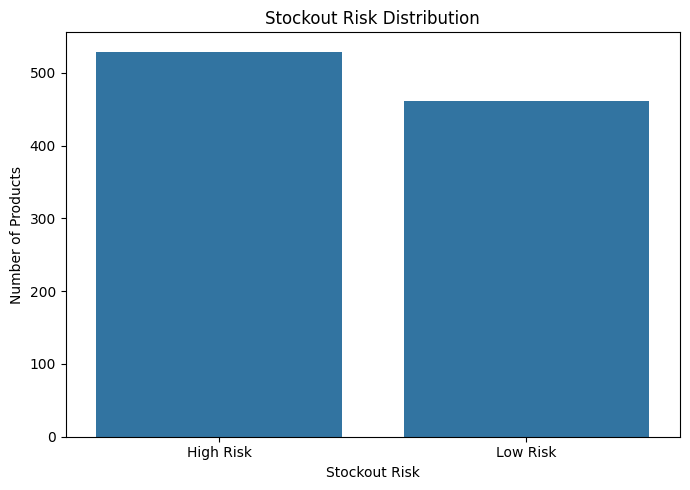

In [218]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='Stockout_Risk'
)

plt.title('Stockout Risk Distribution')
plt.xlabel('Stockout Risk')
plt.ylabel('Number of Products')
plt.tight_layout()
plt.show()

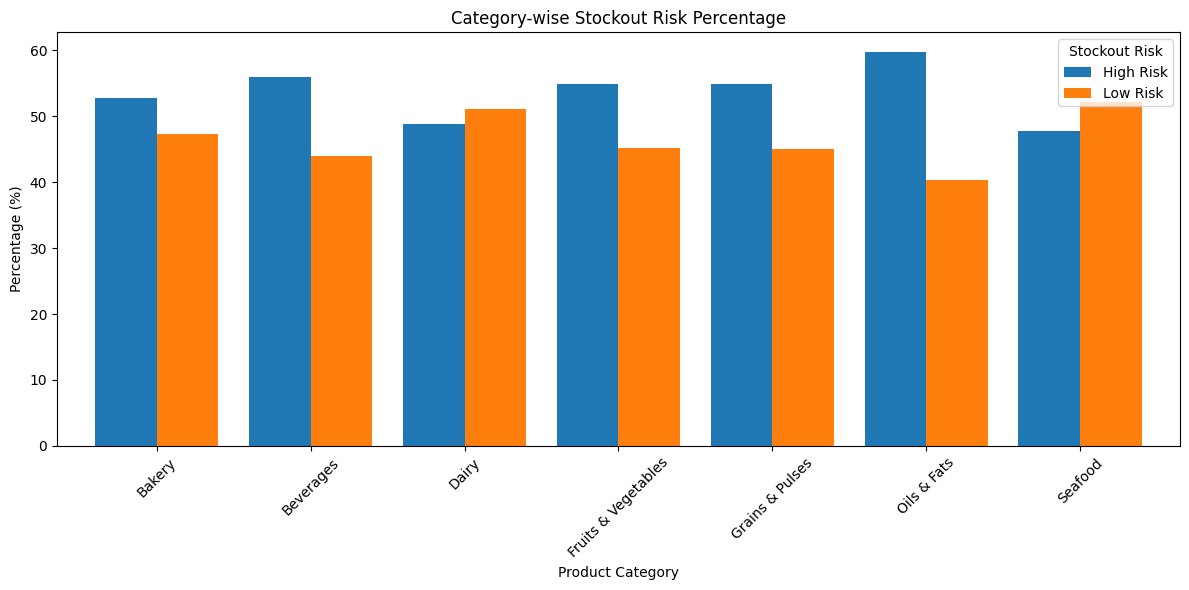

In [219]:
risk_plot = category_risk_percentage.reset_index()

risk_plot.plot(
    x='Category',
    kind='bar',
    figsize=(12, 6),
    width=0.8
)

plt.title('Category-wise Stockout Risk Percentage')
plt.xlabel('Product Category')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=45)
plt.legend(title='Stockout Risk')
plt.tight_layout()
plt.show()

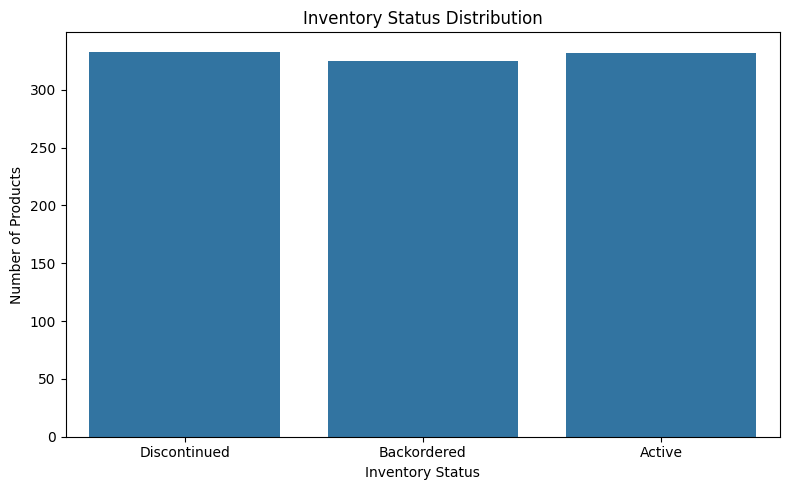

In [220]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Status'
)

plt.title('Inventory Status Distribution')
plt.xlabel('Inventory Status')
plt.ylabel('Number of Products')
plt.tight_layout()
plt.show()

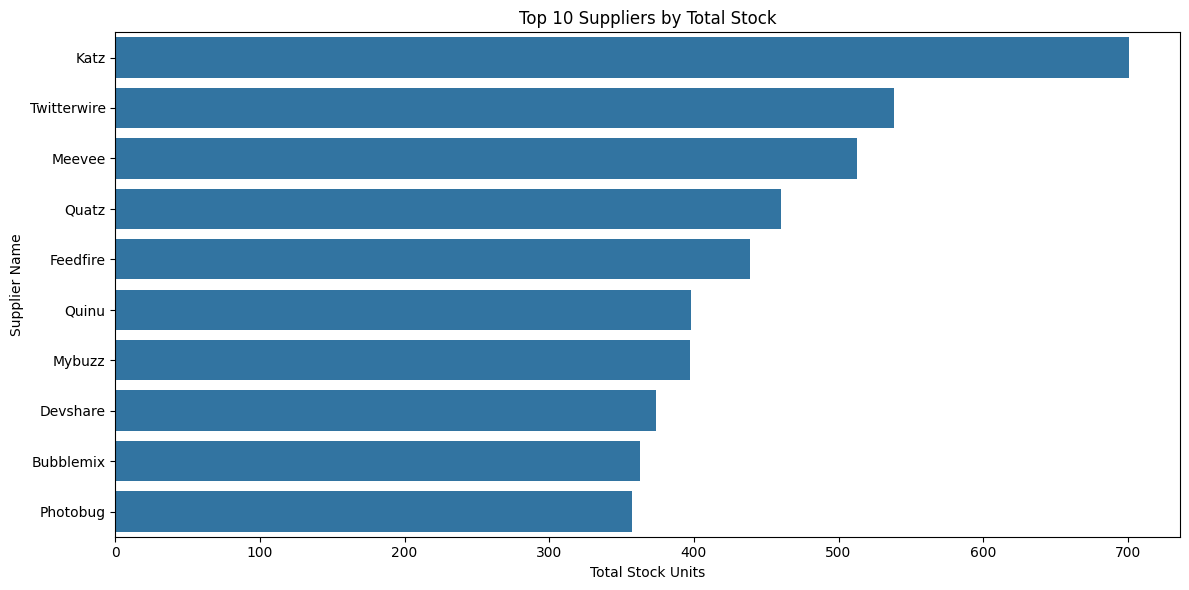

In [221]:
# STEP 37: Top 10 Suppliers

top_suppliers = supplier_analysis.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_suppliers,
    x='Total_Stock',
    y='Supplier_Name'
)

plt.title('Top 10 Suppliers by Total Stock')
plt.xlabel('Total Stock Units')
plt.ylabel('Supplier Name')
plt.tight_layout()
plt.show()

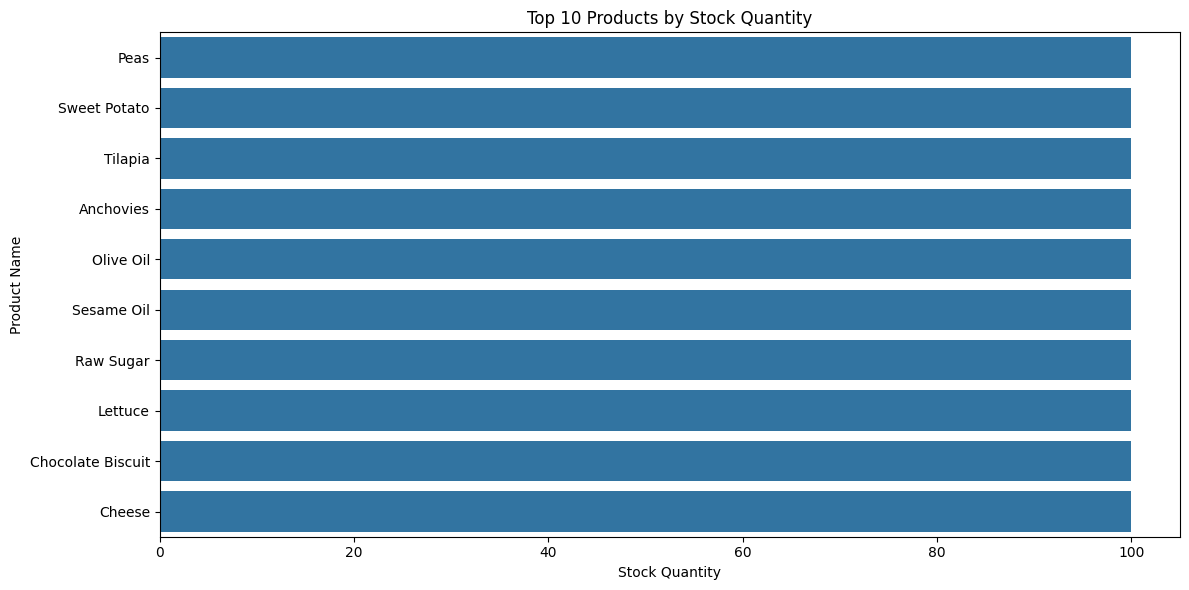

In [222]:
# STEP 38: Top 10 Products by Stock

top_stock_products = df.sort_values(
    by='Stock_Quantity',
    ascending=False
).head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_stock_products,
    x='Stock_Quantity',
    y='Product_Name'
)

plt.title('Top 10 Products by Stock Quantity')
plt.xlabel('Stock Quantity')
plt.ylabel('Product Name')
plt.tight_layout()
plt.show()

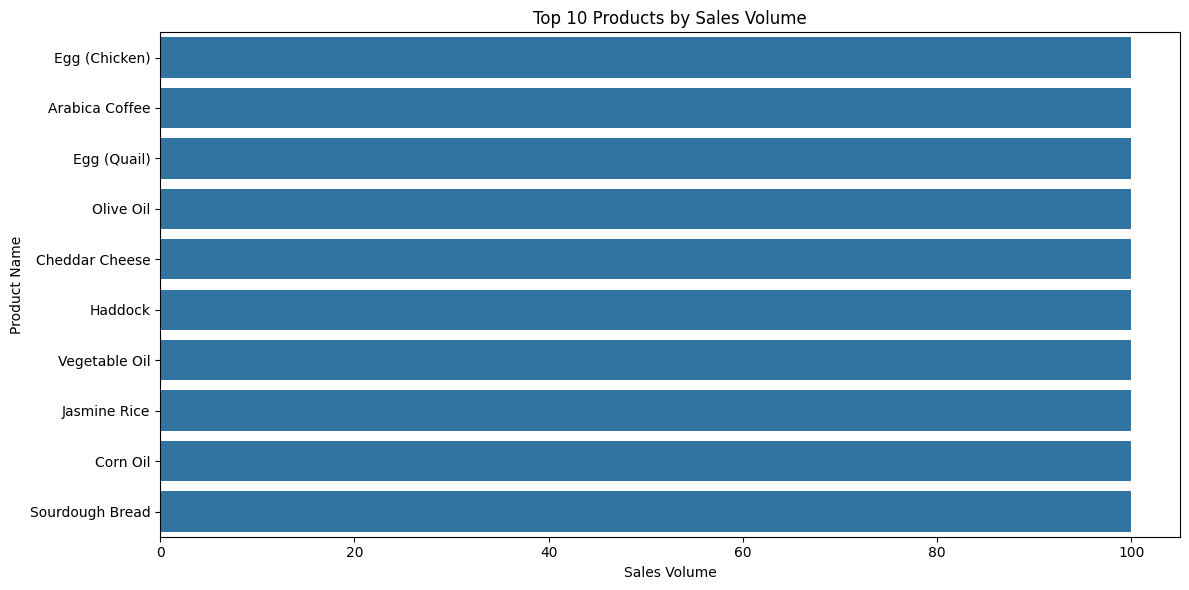

In [223]:
# STEP 39: Top 10 Products by Sales

top_sales_products = df.sort_values(
    by='Sales_Volume',
    ascending=False
).head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_sales_products,
    x='Sales_Volume',
    y='Product_Name'
)

plt.title('Top 10 Products by Sales Volume')
plt.xlabel('Sales Volume')
plt.ylabel('Product Name')
plt.tight_layout()
plt.show()

CORRELATION MATRIX


,Stock_Quantity,Reorder_Level,Reorder_Quantity,Unit_Price,Sales_Volume,Inventory_Turnover_Rate,Days_To_Expiry
Stock_Quantity,1.00,-0.02,-0.02,0.04,0.03,0.04,0.03
Reorder_Level,-0.02,1.00,0.03,-0.05,0.01,0.00,0.05
Reorder_Quantity,-0.02,0.03,1.00,0.01,-0.02,-0.06,-0.01
Unit_Price,0.04,-0.05,0.01,1.00,-0.01,-0.03,-0.01
Sales_Volume,0.03,0.01,-0.02,-0.01,1.00,0.06,0.03
Inventory_Turnover_Rate,0.04,0.00,-0.06,-0.03,0.06,1.00,0.00
Days_To_Expiry,0.03,0.05,-0.01,-0.01,0.03,0.00,1.00


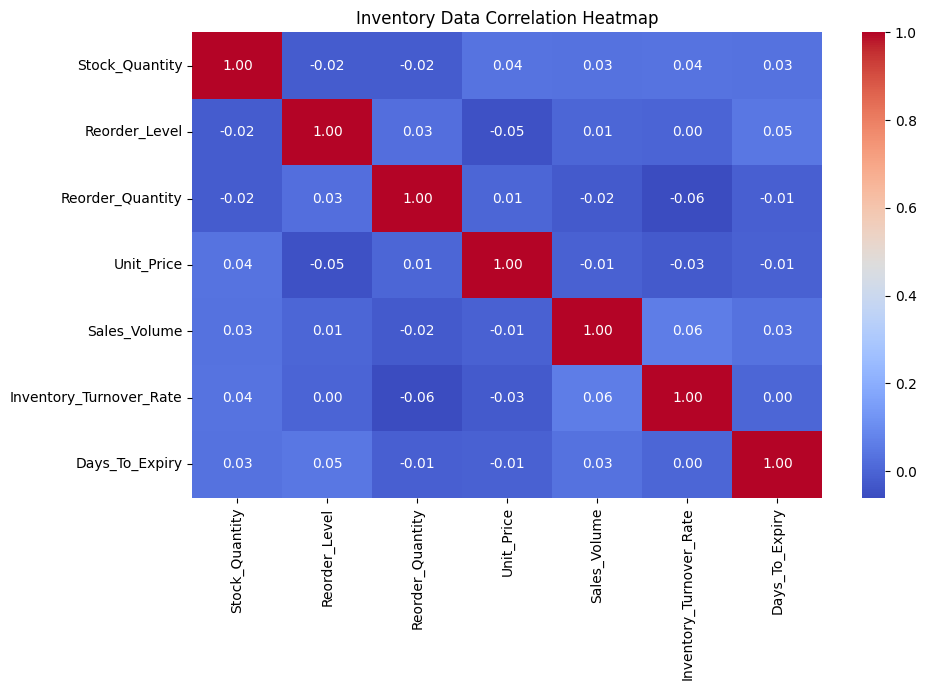

In [224]:
# STEP 40: Correlation Analysis

numeric_df = df.select_dtypes(include=np.number)

correlation_matrix = numeric_df.corr()

print("CORRELATION MATRIX")

display(correlation_matrix.round(2))

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Inventory Data Correlation Heatmap')
plt.tight_layout()
plt.show()

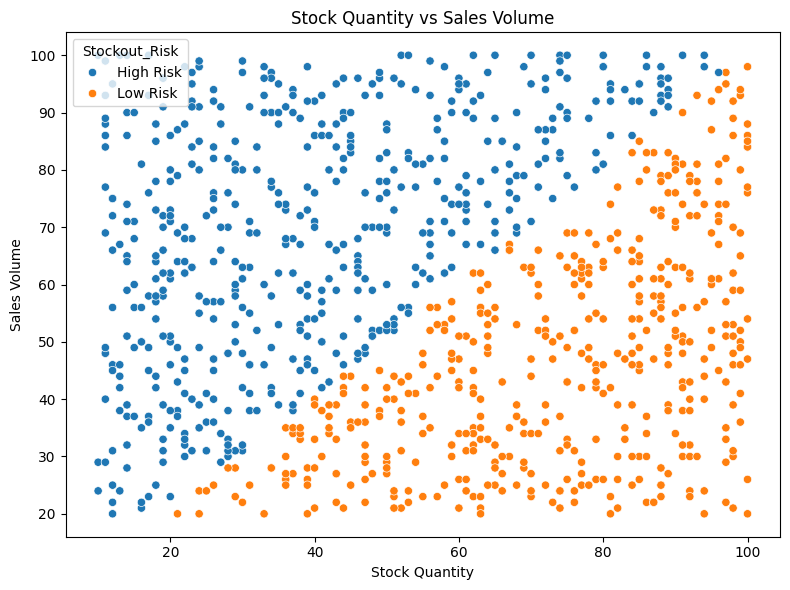

In [225]:
# STEP 41: Stock vs Sales Analysis

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x='Stock_Quantity',
    y='Sales_Volume',
    hue='Stockout_Risk'
)

plt.title('Stock Quantity vs Sales Volume')
plt.xlabel('Stock Quantity')
plt.ylabel('Sales Volume')
plt.tight_layout()
plt.show()

In [226]:
invalid_expiry_dates = df[
    df['Expiration_Date'] < df['Date_Received']
]

print("Records where Expiration Date is before Received Date:",
      len(invalid_expiry_dates))

display(invalid_expiry_dates[
    ['Product_ID', 'Product_Name',
     'Date_Received', 'Expiration_Date']
].head(10))

Records where Expiration Date is before Received Date: 496


,Product_ID,Product_Name,Date_Received,Expiration_Date
1,40-681-9981,Arabica Coffee,2024-11-01,2024-05-08
3,71-594-6552,Long Grain Rice,2024-12-08,2024-04-17
5,21-120-6238,All-Purpose Flour,2024-12-03,2024-09-05
9,46-452-9419,Egg (Duck),2024-11-18,2024-07-08
11,42-220-9305,White Sugar,2024-10-19,2024-10-14
12,75-094-1179,Rye Bread,2024-12-13,2024-07-18
16,55-936-2406,Bread Flour,2024-11-16,2024-04-05
17,82-041-7211,Swiss Cheese,2024-09-10,2024-07-01
18,48-414-6162,Arabica Coffee,2024-05-29,2024-05-05
20,25-349-7974,Spinach,2024-10-07,2024-06-22


In [227]:
invalid_order_expiry = df[
    df['Last_Order_Date'] > df['Expiration_Date']
]

print("Records where Last Order Date is after Expiration Date:",
      len(invalid_order_expiry))

display(invalid_order_expiry[
    ['Product_ID', 'Product_Name',
     'Last_Order_Date', 'Expiration_Date']
].head(10))

Records where Last Order Date is after Expiration Date: 503


,Product_ID,Product_Name,Last_Order_Date,Expiration_Date
1,40-681-9981,Arabica Coffee,2024-05-29,2024-05-08
3,71-594-6552,Long Grain Rice,2025-02-19,2024-04-17
4,57-437-1828,Plum,2024-10-11,2024-10-05
9,46-452-9419,Egg (Duck),2024-11-14,2024-07-08
11,42-220-9305,White Sugar,2024-12-11,2024-10-14
12,75-094-1179,Rye Bread,2025-02-09,2024-07-18
13,11-073-0189,Plum,2024-09-21,2024-05-06
14,22-621-2774,Strawberries,2024-06-30,2024-06-14
18,48-414-6162,Arabica Coffee,2024-11-08,2024-05-05
19,76-854-0095,White Sugar,2025-02-08,2024-12-28


In [228]:
invalid_order_dates = df[
    df['Last_Order_Date'] < df['Date_Received']
]

print("Records where Last Order Date is before Received Date:",
      len(invalid_order_dates))

display(invalid_order_dates[
    ['Product_ID', 'Product_Name',
     'Date_Received', 'Last_Order_Date']
].head(10))

Records where Last Order Date is before Received Date: 475


,Product_ID,Product_Name,Date_Received,Last_Order_Date
0,29-205-1132,Sushi Rice,2024-08-16,2024-06-29
1,40-681-9981,Arabica Coffee,2024-11-01,2024-05-29
2,06-955-3428,Black Rice,2024-08-03,2024-06-10
5,21-120-6238,All-Purpose Flour,2024-12-03,2024-05-26
7,39-629-5554,Egg (Goose),2025-02-03,2024-04-09
8,66-268-8345,Greek Yogurt,2024-12-04,2024-06-02
9,46-452-9419,Egg (Duck),2024-11-18,2024-11-14
10,51-469-4611,Long Grain Rice,2024-12-18,2024-05-24
16,55-936-2406,Bread Flour,2024-11-16,2024-03-09
17,82-041-7211,Swiss Cheese,2024-09-10,2024-05-19


In [229]:
print("Total Rows:", len(df))
print("Unique Product IDs:", df['Product_ID'].nunique())
print("Duplicate Product IDs:",
      df['Product_ID'].duplicated().sum())

Total Rows: 990
Unique Product IDs: 990
Duplicate Product IDs: 0


In [230]:
print("Total Warehouse Locations:",
      df['Warehouse_Location'].nunique())

print("\nProducts per Warehouse Location:")

display(
    df.groupby('Warehouse_Location')['Product_ID']
    .count()
    .value_counts()
    .sort_index()
)

Total Warehouse Locations: 990

Products per Warehouse Location:


Product_ID
1    990
Name: count, dtype: int64

In [231]:
# STEP 42: Expiration Date Validation

invalid_expiry_dates = df[
    df['Expiration_Date'] < df['Date_Received']
]

print("Records where Expiration Date is before Date Received:",
      len(invalid_expiry_dates))

display(invalid_expiry_dates[
    ['Product_ID', 'Product_Name',
     'Date_Received', 'Expiration_Date']
].head(10))

Records where Expiration Date is before Date Received: 496


,Product_ID,Product_Name,Date_Received,Expiration_Date
1,40-681-9981,Arabica Coffee,2024-11-01,2024-05-08
3,71-594-6552,Long Grain Rice,2024-12-08,2024-04-17
5,21-120-6238,All-Purpose Flour,2024-12-03,2024-09-05
9,46-452-9419,Egg (Duck),2024-11-18,2024-07-08
11,42-220-9305,White Sugar,2024-10-19,2024-10-14
12,75-094-1179,Rye Bread,2024-12-13,2024-07-18
16,55-936-2406,Bread Flour,2024-11-16,2024-04-05
17,82-041-7211,Swiss Cheese,2024-09-10,2024-07-01
18,48-414-6162,Arabica Coffee,2024-05-29,2024-05-05
20,25-349-7974,Spinach,2024-10-07,2024-06-22


In [232]:
# STEP 43: Order Date Validation

invalid_order_dates = df[
    df['Last_Order_Date'] < df['Date_Received']
]

print("Records where Last Order Date is before Date Received:",
      len(invalid_order_dates))

display(invalid_order_dates[
    ['Product_ID', 'Product_Name',
     'Date_Received', 'Last_Order_Date']
].head(10))

Records where Last Order Date is before Date Received: 475


,Product_ID,Product_Name,Date_Received,Last_Order_Date
0,29-205-1132,Sushi Rice,2024-08-16,2024-06-29
1,40-681-9981,Arabica Coffee,2024-11-01,2024-05-29
2,06-955-3428,Black Rice,2024-08-03,2024-06-10
5,21-120-6238,All-Purpose Flour,2024-12-03,2024-05-26
7,39-629-5554,Egg (Goose),2025-02-03,2024-04-09
8,66-268-8345,Greek Yogurt,2024-12-04,2024-06-02
9,46-452-9419,Egg (Duck),2024-11-18,2024-11-14
10,51-469-4611,Long Grain Rice,2024-12-18,2024-05-24
16,55-936-2406,Bread Flour,2024-11-16,2024-03-09
17,82-041-7211,Swiss Cheese,2024-09-10,2024-05-19


In [233]:
# STEP 44: Product ID Validation

print("Total Records:", len(df))
print("Unique Product IDs:", df['Product_ID'].nunique())
print("Duplicate Product IDs:", df['Product_ID'].duplicated().sum())

Total Records: 990
Unique Product IDs: 990
Duplicate Product IDs: 0


In [234]:
# STEP 45: Warehouse Location Validation

print("Total Warehouse Locations:",
      df['Warehouse_Location'].nunique())

print("\nProducts per Warehouse Location:")

display(
    df.groupby('Warehouse_Location')
    .size()
    .value_counts()
    .sort_index()
)

Total Warehouse Locations: 990

Products per Warehouse Location:


1    990
Name: count, dtype: int64

In [235]:
# STEP 46: Final Data Quality Summary

data_quality_summary = pd.DataFrame({
    'Check': [
        'Total Records',
        'Total Columns',
        'Missing Values',
        'Duplicate Rows',
        'Duplicate Product IDs',
        'Invalid Expiration Dates',
        'Invalid Order Dates',
        'Unique Warehouse Locations'
    ],
    'Result': [
        len(df),
        len(df.columns),
        df.isnull().sum().sum(),
        df.duplicated().sum(),
        df['Product_ID'].duplicated().sum(),
        len(invalid_expiry_dates),
        len(invalid_order_dates),
        df['Warehouse_Location'].nunique()
    ]
})

display(data_quality_summary)

,Check,Result
0,Total Records,990
1,Total Columns,20
2,Missing Values,0
3,Duplicate Rows,0
4,Duplicate Product IDs,0
5,Invalid Expiration Dates,496
6,Invalid Order Dates,475
7,Unique Warehouse Locations,990


In [236]:
# STEP 47: Overall Inventory Insights

total_products = df['Product_ID'].nunique()
total_stock = df['Stock_Quantity'].sum()
total_sales = df['Sales_Volume'].sum()

high_risk_count = (df['Stockout_Risk'] == 'High Risk').sum()
high_risk_percentage = (high_risk_count / len(df)) * 100

print("OVERALL INVENTORY INSIGHTS")
print("--------------------------")
print("Total Products:", total_products)
print("Total Stock Units:", total_stock)
print("Total Sales Volume:", total_sales)
print("High Risk Products:", high_risk_count)
print("High Risk Percentage:", round(high_risk_percentage, 2), "%")

OVERALL INVENTORY INSIGHTS
--------------------------
Total Products: 990
Total Stock Units: 55053
Total Sales Volume: 58336
High Risk Products: 529
High Risk Percentage: 53.43 %


In [237]:
# STEP 48: Categories Requiring Attention

category_attention = category_risk_percentage.sort_values(
    by='High Risk',
    ascending=False
)

display(category_attention.round(2))

print("Category with Highest Preliminary Risk:",
      category_attention.index[0])

print("Highest Risk Percentage:",
      round(category_attention.iloc[0]['High Risk'], 2), "%")

Stockout_Risk,High Risk,Low Risk
Category,,
Oils & Fats,59.74,40.26
Beverages,56.00,44.00
Grains & Pulses,54.94,45.06
Fruits & Vegetables,54.82,45.18
Bakery,52.70,47.30
Dairy,48.89,51.11
Seafood,47.78,52.22


Category with Highest Preliminary Risk: Oils & Fats
Highest Risk Percentage: 59.74 %


In [238]:
# STEP 49: Products Requiring Reorder

reorder_products = df[
    df['Stock_Status'] == 'Reorder Required'
].copy()

reorder_products = reorder_products.sort_values(
    by='Stock_Quantity',
    ascending=True
)

print("Products Requiring Reorder:",
      len(reorder_products))

display(reorder_products[
    ['Product_ID', 'Product_Name', 'Category',
     'Stock_Quantity', 'Reorder_Level',
     'Reorder_Quantity', 'Supplier_Name']
].head(15))

Products Requiring Reorder: 465


,Product_ID,Product_Name,Category,Stock_Quantity,Reorder_Level,Reorder_Quantity,Supplier_Name
180,00-357-2313,Avocado Oil,Oils & Fats,10,86,23,Quamba
614,95-449-1286,Egg (Chicken),Dairy,10,17,70,Realfire
617,42-495-7698,Sushi Rice,Grains & Pulses,10,11,29,Latz
618,83-727-0814,Basmati Rice,Grains & Pulses,11,87,64,Yodo
780,88-807-8431,Haddock,Seafood,11,87,43,Eire
139,51-459-5630,Sour Cream,Dairy,11,30,4,Skyvu
837,58-946-5152,Bread Flour,Grains & Pulses,11,77,7,Avaveo
291,07-074-1196,Plum,Fruits & Vegetables,11,56,62,Skajo
860,80-020-8041,Black Rice,Grains & Pulses,11,58,26,Wordware
598,22-266-9291,Sardines,Seafood,11,17,59,Vinder


In [239]:
# STEP 50: High Sales and Low Stock Products

high_sales_low_stock = df[
    (df['Sales_Volume'] >= df['Sales_Volume'].quantile(0.75)) &
    (df['Stock_Quantity'] <= df['Stock_Quantity'].quantile(0.25))
].copy()

high_sales_low_stock = high_sales_low_stock.sort_values(
    by='Sales_Volume',
    ascending=False
)

print("High Sales + Low Stock Products:",
      len(high_sales_low_stock))

display(high_sales_low_stock[
    ['Product_Name', 'Category',
     'Stock_Quantity', 'Sales_Volume',
     'Reorder_Level', 'Supplier_Name']
].head(15))

High Sales + Low Stock Products: 62


,Product_Name,Category,Stock_Quantity,Sales_Volume,Reorder_Level,Supplier_Name
614,Egg (Chicken),Dairy,10,100,17,Realfire
977,Lime,Fruits & Vegetables,14,100,75,Camido
680,Watermelon,Fruits & Vegetables,13,100,88,Dabjam
241,Haddock,Seafood,17,100,38,Buzzdog
978,Avocado Oil,Oils & Fats,24,99,89,Voolith
397,Haddock,Seafood,30,99,81,Youtags
758,Plum,Fruits & Vegetables,11,99,58,Yambee
109,Sardines,Seafood,33,98,18,Eayo
166,Asparagus,Fruits & Vegetables,22,98,40,Devpoint
819,Rice Flour,Grains & Pulses,24,98,2,Quatz


In [240]:
# STEP 51: Business Recommendations Summary

recommendations = pd.DataFrame({
    'Business Area': [
        'Inventory Management',
        'Stockout Risk',
        'Category Management',
        'Reorder Planning',
        'Product Monitoring',
        'Data Quality'
    ],
    'Recommendation': [
        'Regularly monitor stock quantities.',
        'Investigate products flagged as high risk.',
        'Review categories with higher preliminary risk.',
        'Prioritize products at or below reorder level.',
        'Monitor high-sales and low-stock products.',
        'Validate date fields and dataset assumptions.'
    ]
})

display(recommendations)

,Business Area,Recommendation
0,Inventory Management,Regularly monitor stock quantities.
1,Stockout Risk,Investigate products flagged as high risk.
2,Category Management,Review categories with higher preliminary risk.
3,Reorder Planning,Prioritize products at or below reorder level.
4,Product Monitoring,Monitor high-sales and low-stock products.
5,Data Quality,Validate date fields and dataset assumptions.


In [241]:
# STEP 52: Final Project KPIs

final_kpis = pd.DataFrame({
    'KPI': [
        'Total Products',
        'Total Stock Units',
        'Total Sales Volume',
        'Average Stock Quantity',
        'Average Unit Price',
        'High Risk Products',
        'Reorder Required Products'
    ],
    'Value': [
        df['Product_ID'].nunique(),
        df['Stock_Quantity'].sum(),
        df['Sales_Volume'].sum(),
        round(df['Stock_Quantity'].mean(), 2),
        round(df['Unit_Price'].mean(), 2),
        (df['Stockout_Risk'] == 'High Risk').sum(),
        (df['Stock_Status'] == 'Reorder Required').sum()
    ]
})

display(final_kpis)

,KPI,Value
0,Total Products,990.00
1,Total Stock Units,55053.00
2,Total Sales Volume,58336.00
3,Average Stock Quantity,55.61
4,Average Unit Price,5.92
5,High Risk Products,529.00
6,Reorder Required Products,465.00


In [242]:
# STEP 53: Final Category Performance

final_category_report = df.groupby('Category').agg(
    Total_Products=('Product_ID', 'count'),
    Total_Stock=('Stock_Quantity', 'sum'),
    Total_Sales=('Sales_Volume', 'sum'),
    Average_Stock=('Stock_Quantity', 'mean'),
    Average_Price=('Unit_Price', 'mean')
).reset_index()

display(final_category_report.round(2))

,Category,Total_Products,Total_Stock,Total_Sales,Average_Stock,Average_Price
0,Bakery,74,4175,4564,56.42,4.06
1,Beverages,75,3822,4533,50.96,16.00
2,Dairy,180,10534,10772,58.52,4.51
3,Fruits & Vegetables,332,18558,19397,55.90,4.80
4,Grains & Pulses,162,8240,8886,50.86,3.85
5,Oils & Fats,77,4123,4606,53.55,4.24
6,Seafood,90,5601,5578,62.23,11.23


In [243]:
# STEP 54: Final Product Risk Report

final_risk_report = df[
    ['Product_ID', 'Product_Name', 'Category',
     'Stock_Quantity', 'Sales_Volume',
     'Reorder_Level', 'Stock_Status', 'Stockout_Risk']
].copy()

final_risk_report = final_risk_report.sort_values(
    by=['Stockout_Risk', 'Stock_Quantity'],
    ascending=[True, True]
)

display(final_risk_report.head(20))

,Product_ID,Product_Name,Category,Stock_Quantity,Sales_Volume,Reorder_Level,Stock_Status,Stockout_Risk
180,00-357-2313,Avocado Oil,Oils & Fats,10,24,86,Reorder Required,High Risk
614,95-449-1286,Egg (Chicken),Dairy,10,100,17,Reorder Required,High Risk
617,42-495-7698,Sushi Rice,Grains & Pulses,10,29,11,Reorder Required,High Risk
139,51-459-5630,Sour Cream,Dairy,11,84,30,Reorder Required,High Risk
193,20-054-3716,Chocolate Biscuit,Bakery,11,88,6,Sufficient Stock,High Risk
291,07-074-1196,Plum,Fruits & Vegetables,11,40,56,Reorder Required,High Risk
422,84-269-9130,Long Grain Rice,Grains & Pulses,11,48,10,Sufficient Stock,High Risk
425,88-951-9038,Black Coffee,Beverages,11,89,72,Reorder Required,High Risk
472,06-996-3221,Evaporated Milk,Dairy,11,48,9,Sufficient Stock,High Risk
598,22-266-9291,Sardines,Seafood,11,69,17,Reorder Required,High Risk


In [244]:
# STEP 55: Export Reports

final_kpis.to_csv('Final_KPI_Report.csv', index=False)

final_category_report.to_csv(
    'Final_Category_Report.csv',
    index=False
)

final_risk_report.to_csv(
    'Final_Product_Risk_Report.csv',
    index=False
)

recommendations.to_csv(
    'Business_Recommendations.csv',
    index=False
)

print("All reports exported successfully!")

All reports exported successfully!


In [245]:
# STEP 56: Export Cleaned Dataset

df.to_csv('Cleaned_Retail_Inventory_Dataset.csv', index=False)

print("Cleaned dataset exported successfully!")
print("Total Rows:", len(df))
print("Total Columns:", len(df.columns))

Cleaned dataset exported successfully!
Total Rows: 990
Total Columns: 20


## 1. Project Overview

This project focuses on analyzing retail inventory data to understand stock levels, sales volume, reorder requirements, supplier performance, and potential stockout risks.

The analysis helps identify inventory management challenges and supports data-driven business decisions.

## 2. Business Objectives

- Analyze overall inventory performance.
- Identify products requiring reorder.
- Evaluate potential stockout risks.
- Compare inventory across product categories.
- Analyze supplier-wise inventory distribution.
- Examine product expiration dates.
- Identify high-sales and low-stock products.
- Provide actionable business recommendations.

## 3. Tools & Libraries

- Python 3.10.5
- Pandas – Data manipulation and analysis
- NumPy – Numerical operations
- Matplotlib – Data visualization
- Seaborn – Statistical visualization
- Jupyter Notebook – Development environment

## 4. Dataset Information

The dataset contains retail inventory records with information about:

- Product details
- Product categories
- Supplier information
- Stock quantity
- Reorder levels and quantities
- Unit prices
- Received, order, and expiration dates
- Warehouse locations
- Sales volume
- Inventory turnover rate
- Product status

## 5. Data Loading

The grocery inventory dataset was imported into Python using the Pandas library.

The dataset was loaded from a CSV file for further data cleaning, exploration, and analysis.

The initial dataset contained 990 rows and 16 columns.

## 6. Data Cleaning & Preparation

The following data cleaning activities were performed:

- Renamed the Catagory column to Category.
- Handled one missing Category value using product classification.
- Removed the currency symbol from Unit_Price and converted it into numeric format.
- Converted date columns into datetime format.
- Checked for missing values.
- Checked for duplicate records.
- Verified data types.

After cleaning, no missing values or duplicate rows remained.

## 7. Exploratory Data Analysis (EDA)

Exploratory Data Analysis was performed to understand the dataset and identify patterns.

The analysis included:

- Overall inventory overview.
- Category-wise inventory analysis.
- Stock quantity distribution.
- Sales volume analysis.
- Product status analysis.
- Supplier-wise inventory analysis.
- Warehouse location analysis.

## 8. Inventory & Stockout Risk Analysis

Inventory analysis was performed to identify products that may require attention.

The following activities were completed:

- Identified products requiring reorder.
- Classified products into preliminary stockout risk categories.
- Calculated overall stockout risk percentages.
- Compared stockout risk across product categories.
- Analyzed products with high sales volume and low stock.
- Examined product expiration dates.

## 9. Supplier & Business Analysis

Supplier and business performance were explored through:

- Supplier-wise stock analysis.
- Top 10 suppliers by total stock.
- Category-wise stock and sales comparison.
- Product-level stock and sales analysis.
- Correlation analysis.
- Stock quantity versus sales volume analysis.

These analyses helped identify areas requiring further inventory investigation.

## 10. Data Visualization

Visualizations were created using Matplotlib and Seaborn to understand inventory patterns.

The following charts were generated:

- Category-wise Total Stock.
- Stockout Risk Distribution.
- Category-wise Stockout Risk Percentage.
- Inventory Status Distribution.
- Top 10 Suppliers by Total Stock.
- Top 10 Products by Stock Quantity.
- Top 10 Products by Sales Volume.
- Inventory Data Correlation Heatmap.
- Stock Quantity vs Sales Volume Scatter Plot.

These visualizations help communicate inventory patterns and potential areas of concern.

## 11. Key Findings

The analysis revealed the following findings:

1. The dataset contains 990 product records across 7 product categories.

2. Total inventory stock is 55,053 units.

3. Total sales volume is 58,336 units.

4. Approximately 53.43% of product records were classified as High Risk under the preliminary stockout screening method.

5. Oils & Fats recorded the highest preliminary High Risk percentage at 59.74%.

6. Seafood recorded the lowest preliminary High Risk percentage at 47.78%.

7. Katz was the supplier with the highest total stock among the suppliers analyzed, with 701 units.

8. All 990 records were classified as expired when compared with the current analysis date. However, the dataset contains historical dates, so this should not be interpreted as proof of actual current inventory expiry.

## 12. Data Limitations

The following limitations were identified during the analysis:

- The dataset contains historical date values.
- Some expiration dates occur before the corresponding received dates.
- The sales volume reporting period is not specified.
- Stockout risk classification is based on a preliminary comparison between stock quantity and sales volume.
- Warehouse locations appear to be highly granular, limiting meaningful warehouse-level comparisons.
- The dataset may not represent actual real-world retail operations.

Therefore, the findings should be treated as exploratory insights rather than confirmed business outcomes.

## 13. Business Recommendations

Based on the exploratory analysis, the following recommendations are suggested:

1. Regularly monitor stock quantities and reorder levels.
2. Investigate products classified as High Risk.
3. Review inventory levels in categories with higher preliminary risk percentages.
4. Prioritize products with high sales volume and relatively low stock.
5. Monitor discontinued products and investigate their remaining inventory.
6. Review supplier-wise stock distribution.
7. Validate expiration and transaction dates before making inventory decisions.
8. Improve inventory tracking through reliable and consistent data collection.

## 14. Conclusion

This project explored retail inventory data using Python and its data analysis libraries.

Through data cleaning, exploratory data analysis, statistical summaries, and visualizations, the project examined stock levels, sales volume, reorder requirements, supplier distribution, and preliminary stockout risks.

The analysis identified potential inventory management concerns and highlighted areas that may require further investigation.

This project demonstrates the practical application of Python, Pandas, NumPy, Matplotlib, and Seaborn in analyzing structured retail data and communicating data-driven business insights.

The findings also highlight the importance of data quality and careful interpretation when making business recommendations.